In [4]:
#import cell
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error
from prettytable import PrettyTable
from utils import stats, exploration_plots

**importing the data**

In [2]:
df = pd.read_csv("development.csv", header = "infer")
evaluate_df = pd.read_csv("evaluation.csv", header = "infer")

**Starting the data cleaning**

In [7]:
missing_per_feature = df.isnull().sum()
print(missing_per_feature)

category            0
title               0
body                0
amenities       12804
bathrooms          51
bedrooms           89
currency            0
fee                 0
has_photo           0
pets_allowed    48320
price               0
price_type          0
square_feet         0
address         73226
cityname          234
state             234
latitude           23
longitude          23
source              0
time                0
id                  0
dtype: int64


In [ ]:
#fixing problems related to the missing values in features
for i in range(len(df)):
    #if there is a missing values in pets allowed, i insert the string "no"
    if pd.isnull(df.iloc[i]["pets_allowed"]):
        df.loc[i, "pets_allowed"] = "no"
    
    if pd.isnull(df.iloc[i]["amenities"]):
        df.loc[i, "amenities"] = "none"
    #checking now for the missing values in bathroom and bethrooms
    #i assign the value 0 if there are missing value
    if pd.isnull(df.iloc[i]["bathrooms"]):
        df.loc[i, "bathrooms"] = 1
    if pd.isnull(df.iloc[i]["bedrooms"]):
        df.loc[i, "bedrooms"] = 1




In [5]:
stats(df)
stats(evaluate_df)
#now i want to explore the relationships between the features and the price:

NameError: name 'print_stats' is not defined

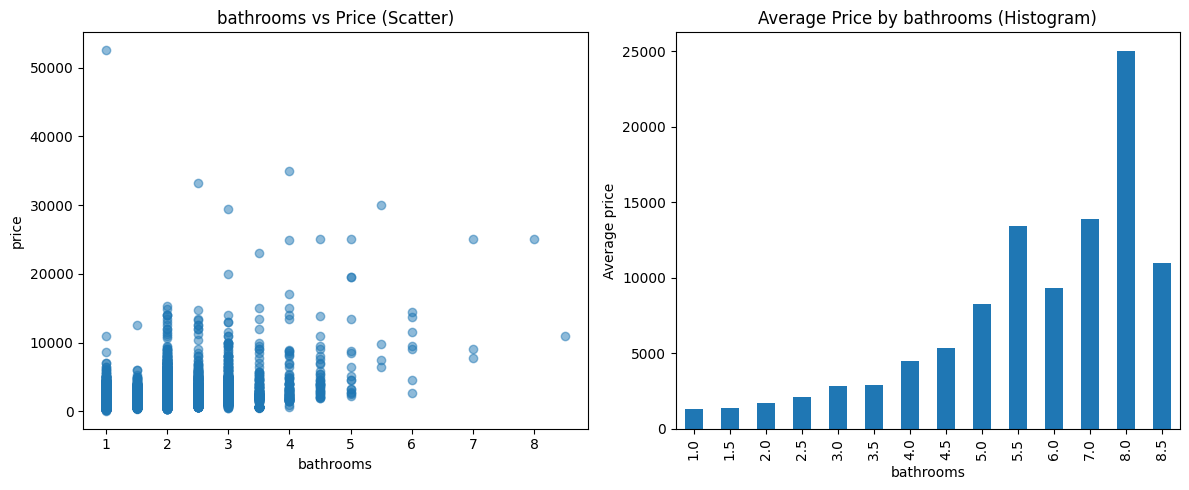

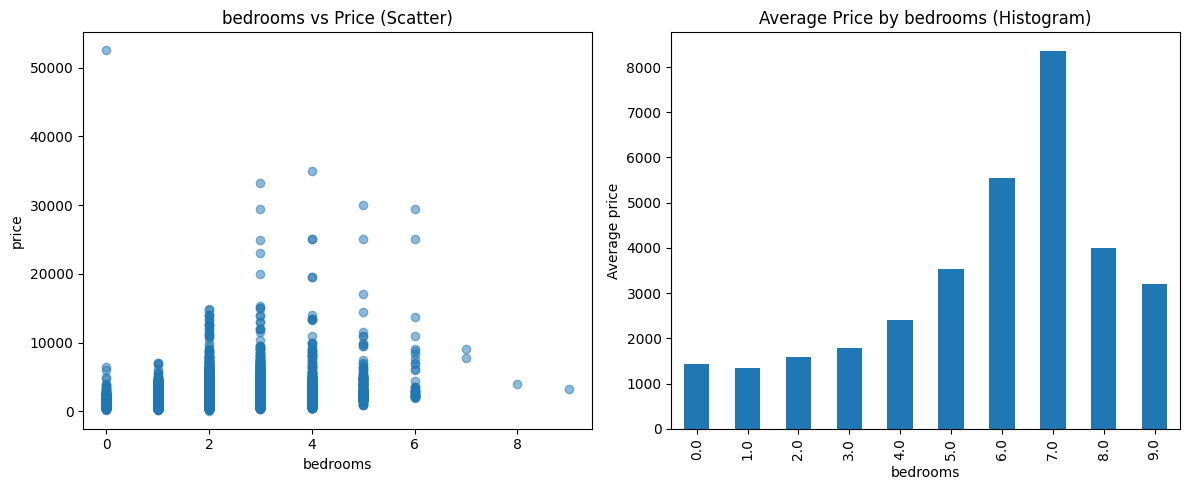

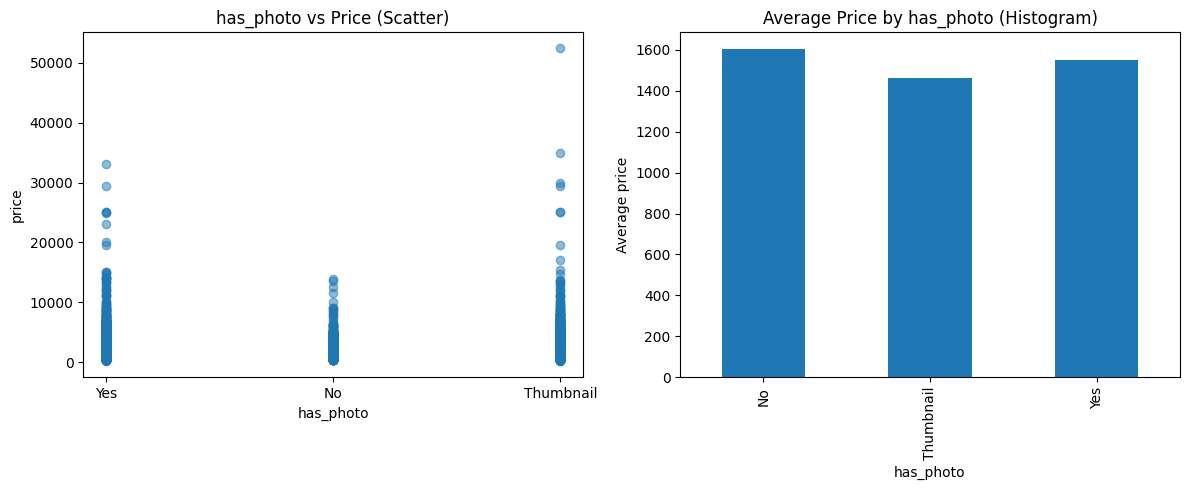

TypeError: 'value' must be an instance of str or bytes, not a float

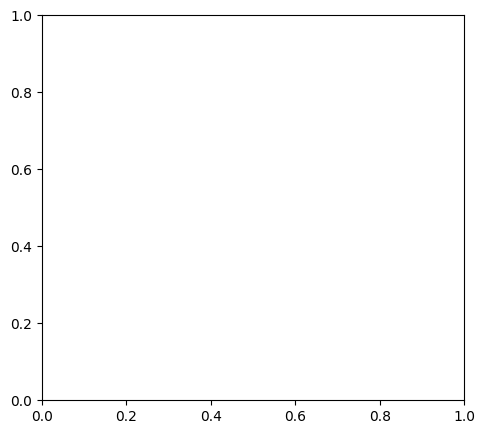

In [6]:
features = ["bathrooms", "bedrooms", "has_photo", "pets_allowed", "square_feet", "time"]
exploration_plots(df, features)

In [ ]:
if "address" in df.columns:
    df = df.drop(columns="address")
# Drop 'title' and 'body' columns if they exist
for col in ["title", "body", "amenities"]:
    if col in df.columns:
        df = df.drop(columns=col)



In [7]:
df = df.dropna()
type(df)

pandas.core.frame.DataFrame

In [12]:
# Separate features and target
table = PrettyTable()

# Encode all categorical columns
categorical_cols = df.select_dtypes(include=['object', 'category']).columns
X_encoded = pd.get_dummies(df, columns=categorical_cols)
y = X_encoded["price"]
X_encoded = X_encoded.drop(columns ="price")

# Split into train and test sets
X_train, X_test, y_train, y_test = train_test_split(X_encoded, y, test_size=0.2, random_state=42)

rfr = RandomForestRegressor()
rfr.fit(X_train, y_train)
y_pred = rfr.predict(X_test)
mae = mean_absolute_error(y_test, y_pred)
table.field_names = ["Metric", "value"]
table.add_row(["Mean Absolute Error", mae])
print(table)


+---------------------+-------------------+
|        Metric       |       value       |
+---------------------+-------------------+
| Mean Absolute Error | 182.7726966920799 |
+---------------------+-------------------+


In [11]:
print(len(X_encoded))
print(len(df))

79355
79355


da fare
- data exploration evaluation set
- assegnazioni valori a bathrooms and bedrooms
- trovare valori states tramite longitute e latitude più vicine
- distribuzione stati nel dataset (evaluation e train)
- gestire i campi title e body con tf-Idf
- trovare i valori di quali valute si usano
